# Parte 1 — O primeiro modelo em produção

**Banco Aurora · Prevenção a Fraudes** · entrega: **quarta-feira, 11/11, 23h59**

Leia antes o `demanda_parte1.md`: é o pedido do negócio. Este notebook é o roteiro técnico para atendê-lo.

**Como este notebook funciona**
- Cada seção diz **o que** fazer e **por quê**. O código é seu.
- Duas células vêm prontas (seção 0 e seção 10): elas são encanamento, não conteúdo.
- Tudo que será reutilizado nas partes 2 e 3 vai para arquivos `.py` (`features.py`, `monitoramento.py`), não fica só no notebook.
- Rode a partir da raiz do projeto, com o **MLflow** e o **sistema** no ar (veja o `README.md`).

**O que será avaliado nesta parte**
1. O contrato de features é respeitado no treino e na inferência.
2. O modelo está registrado e rastreável no MLflow, como `@champion`.
3. O threshold é justificado pelo custo de negócio.
4. O monitoramento está pronto **antes** do primeiro lote chegar.

O algoritmo é escolha sua. **Não existe ranking de performance**: existe um piso (seção 5) e existe a qualidade da justificativa.

## 0. Ambiente

Rode a célula abaixo. Se algo aparecer como `FALHOU`, resolva antes de seguir: o resto do notebook depende das quatro conexões.

In [1]:
# CÉLULA PRONTA — só rode. Tudo precisa aparecer como "ok".
import json
import urllib.request

import mlflow
import psycopg2

import config

for nome, uri in [("Postgres / antifraude", config.URI_BANCO_APP), ("Postgres / mlflow", config.URI_BANCO_MLFLOW)]:
    try:
        psycopg2.connect(uri).close()
        print(f"{nome:24} ok")
    except Exception as e:
        print(f"{nome:24} FALHOU -> {e}")

for nome, url in [("MLflow", f"{config.MLFLOW_TRACKING_URI}/health"), ("Sistema", f"{config.SISTEMA_URL}/saude")]:
    try:
        resp = urllib.request.urlopen(url, timeout=5).read().decode()
        print(f"{nome:24} ok -> {resp[:160]}")
    except Exception as e:
        print(f"{nome:24} FALHOU -> {e}")

mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
print("\ntracking uri:", mlflow.get_tracking_uri())

Postgres / antifraude    ok
Postgres / mlflow        ok
MLflow                   ok -> OK
Sistema                  ok -> {"sistema":"ok","contrato":"1.0","modelo":{"ok":false,"erro":"Não há 'antifraude@champion' no MLflow (http://127.0.0.1:5000). Registre um modelo e aponte o alia

tracking uri: http://127.0.0.1:5000


## 1. O contrato

O contrato (`contrato/contrato_features.yaml`) é o acordo com o time de Plataforma: as 13 features que o sistema de produção entrega, com tipo, regra de cálculo e valores permitidos. **O sistema rejeita qualquer lote que não o respeite**, e o seu modelo vai receber exatamente isso — nada mais.

**Faça**
1. Leia o YAML com `yaml.safe_load` e monte, a partir dele (não digitando à mão), a lista das features na ordem do contrato, separando categóricas e numéricas.
2. Carregue `dados/transacoes_semanas_01_12.csv` e `dados/rotulos_semanas_01_12.csv` e junte os dois pela `id_transacao`. Garanta que a junção é 1 para 1 e que nenhuma linha se perdeu.
3. Escreva uma validação do histórico contra o contrato: colunas presentes, tipos, valores fora da lista nas categóricas, valores fora de `min`/`max`, nulos. O histórico passa?

> Por que validar um dado que "veio do próprio banco"? Porque o modelo vai aprender o que estiver aqui. Se o treino tiver algo que a produção não terá (ou o contrário), o erro só aparece depois, em produção.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
from app import contrato as regras
from features import preprocessador
from monitoramento import custo, drift, saida, desempenho

contrato = regras.carregar()
colunas = regras.nomes_features(contrato)
categoricas = [f["nome"] for f in contrato["features"] if f["tipo"] == "categoria"]
numericas = [nome for nome in colunas if nome not in categoricas]
transacoes = pd.read_csv("dados/transacoes_semanas_01_12.csv")
rotulos = pd.read_csv("dados/rotulos_semanas_01_12.csv")
assert transacoes.id_transacao.notna().all() and rotulos.id_transacao.notna().all()
historico = transacoes.merge(rotulos, on="id_transacao", how="outer",
                            validate="one_to_one", indicator=True)
assert historico["_merge"].eq("both").all()
assert historico.fraude.isin([0, 1]).all()
for semana, lote in historico.groupby("semana"):
    _, erros = regras.validar(lote, contrato)
    assert not erros, (semana, erros)
assert set(historico.semana) == set(range(1, 13))
historico = regras.tipar(historico, contrato)
print(f"Contrato {contrato['versao']} validado: {len(historico):,} transações e rótulos.")

Contrato 1.0 validado: 240,384 transações e rótulos.


## 2. Divisão temporal

A regra combinada com o negócio: **treino nas semanas 1 a 10, validação nas semanas 11 e 12**.

**Faça**
1. Separe os dois conjuntos pela coluna `semana`.
2. Mostre a taxa de fraude por semana e o tamanho de cada conjunto.
3. Responda em uma célula de texto: por que uma divisão aleatória (`train_test_split`) seria um erro aqui?

In [3]:
treino = historico[historico.semana.between(1, 10)]
validacao = historico[historico.semana.isin([11, 12])]
X_treino, X_val = treino[colunas], validacao[colunas]
y_treino, y_val = treino.fraude, validacao.fraude
display(historico.groupby("semana").fraude.agg(transacoes="size", taxa_fraude="mean"))
print(f"Treino: {len(treino):,} | Validação: {len(validacao):,}")

,transacoes,taxa_fraude
semana,,
1,20160,0.014732
2,19811,0.014235
3,20283,0.012276
4,19995,0.013153
5,20318,0.018260
6,20479,0.014551
7,20307,0.013641
8,19706,0.015528
9,20006,0.011696


Treino: 200,887 | Validação: 39,497


Uma divisão aleatória permitiria que semanas futuras influenciassem o treino, além de misturar observações próximas no tempo. A divisão cronológica simula a aplicação do modelo a semanas ainda não observadas e preserva o recorte exigido.

## 3. Pré-processamento em `features.py`

Escreva no arquivo `features.py` (não no notebook) o que transforma as 13 features cruas na entrada do seu algoritmo. Depois, importe aqui.

**Requisitos**
- O pré-processamento precisa ser parte do modelo que você registra (um `Pipeline` do scikit-learn). Em produção, o sistema entrega as features cruas e chama `predict_proba` — ele não transforma nada.
- As listas de colunas e de categorias vêm **do contrato**, não do que apareceu no treino. Pense no que acontece se uma UF que não está no treino aparecer em produção.
- Se o seu pipeline usar classes ou funções suas, o modelo precisa ser registrado com `code_paths=["features.py"]`.

> Dica: depois de editar o `features.py`, use `importlib.reload(features)` ou reinicie o kernel.

In [4]:
from sklearn.pipeline import Pipeline

def montar_pipeline(estimador, escalar):
    return Pipeline([
        ("preprocessamento", preprocessador(contrato, escalar=escalar)),
        ("classificador", estimador),
    ])

## 4. Pelo menos dois modelos, tudo no MLflow

Treine **pelo menos dois algoritmos** diferentes, cada um em uma run do MLflow.

**Faça**
1. Crie (ou use) um experimento com nome que você reconheça depois.
2. Em cada run, registre:
   - **parâmetros**: algoritmo, hiperparâmetros relevantes, semanas de treino e de validação, versão do contrato;
   - **métricas na validação**: PR-AUC, recall, precision e **custo** (seção 5);
   - **o modelo** (`mlflow.sklearn.log_model`), com assinatura (`infer_signature`) e um `input_example`.
3. Compare as runs na interface do MLflow.

> Use PR-AUC e não ROC-AUC para comparar ranking: com 1,5% de fraude, a ROC-AUC fica alta até para modelos ruins.

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

candidatos = {
    "Regressão logística": montar_pipeline(LogisticRegression(max_iter=500), True),
    "Gradient boosting": montar_pipeline(
        HistGradientBoostingClassifier(max_iter=200, random_state=42), False),
}

for modelo in candidatos.values():
    modelo.fit(X_treino, y_treino)

## 5. Threshold pelo custo

O `predict_proba` devolve um score. O **threshold** é o corte: `score >= threshold` → bloquear. O padrão de 0,5 não tem nada a ver com o problema do banco.

**Custo de um conjunto de decisões** = soma do **valor** das fraudes aprovadas + **R$ 15** × legítimas bloqueadas.

**Faça**
1. Escreva a função de custo (ela vai para o `monitoramento.py` na seção 9; pode começar aqui).
2. Para cada modelo, varra thresholds de 0,01 a 0,99 na **validação** e escolha o de menor custo. Faça o gráfico custo × threshold.
3. No threshold escolhido, mostre recall, precision e custo. Registre o threshold e o custo como métricas da run.
4. Mostre a comparação com o **piso** pedido pelo negócio:
   - aprovar tudo;
   - a regra atual: bloquear todo Pix acima de R$ 1.000;
   - o próprio modelo com threshold 0,5.

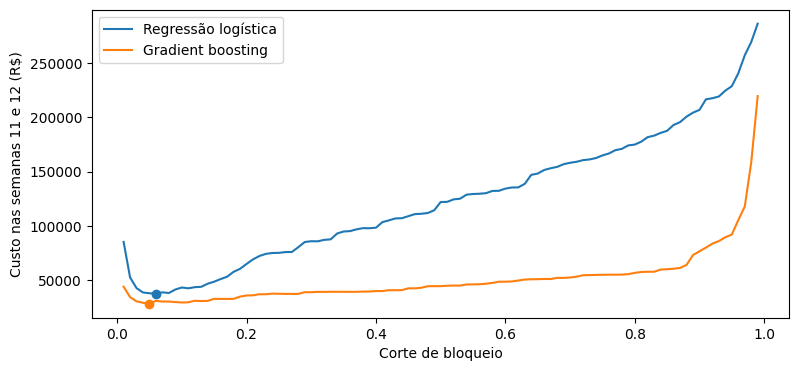

,modelo,política,total,semana 11,semana 12
0,Regressão logística,Aprovar tudo,376035.53,177029.27,199006.26
1,Regressão logística,Pix acima de R$ 1.000,225349.79,102820.44,122529.35
2,Regressão logística,"Corte 0,50",122067.11,63466.50,58600.61
3,Regressão logística,Corte escolhido,37608.05,20068.06,17539.99
4,Gradient boosting,Aprovar tudo,376035.53,177029.27,199006.26
5,Gradient boosting,Pix acima de R$ 1.000,225349.79,102820.44,122529.35
6,Gradient boosting,"Corte 0,50",44638.12,19461.08,25177.04
7,Gradient boosting,Corte escolhido,28448.23,12291.26,16156.97


,segmento,transacoes,fraudes,recall,precision,pr_auc,custo,legitimas_bloqueadas,fraudes_aprovadas,valor_fraude_aprovada
Regressão logística,total,39497,600,0.751667,0.32992,0.672617,37608.05,916,149,23868.05
Gradient boosting,total,39497,600,0.836667,0.471362,0.811493,28448.23,563,98,20003.23


In [6]:
import matplotlib.pyplot as plt

valores = validacao.valor_transacao
referencias = {
    "Aprovar tudo": np.zeros(len(validacao), dtype=bool),
    "Pix acima de R$ 1.000": (validacao.canal.eq("pix") & valores.gt(1000)).to_numpy(),
}
cortes = np.arange(1, 100) / 100
resultados = {}
comparacao = []
fig, eixo = plt.subplots(figsize=(9, 4))
for nome, modelo in candidatos.items():
    score = modelo.predict_proba(X_val)[:, 1]
    curva = [custo(y_val, valores, score >= corte) for corte in cortes]
    indice = int(np.argmin(curva))
    corte = float(cortes[indice])
    pontuadas = validacao.assign(score=score)
    metricas = desempenho(pontuadas, corte).iloc[0].to_dict()
    referencias_modelo = {**referencias, "Corte 0,50": score >= 0.5}
    limites = [custo(y_val, valores, decisao) for decisao in referencias_modelo.values()]
    resultados[nome] = dict(modelo=modelo, corte=corte, dados=pontuadas,
                            metricas=metricas, elegivel=all(curva[indice] < v for v in limites))
    for politica, decisao in {**referencias_modelo, "Corte escolhido": score >= corte}.items():
        linha = {"modelo": nome, "política": politica, "total": custo(y_val, valores, decisao)}
        for semana in (11, 12):
            mascara = validacao.semana.eq(semana).to_numpy()
            linha[f"semana {semana}"] = custo(y_val[mascara], valores[mascara], decisao[mascara])
        comparacao.append(linha)
    eixo.plot(cortes, curva, label=nome)
    eixo.scatter(corte, curva[indice])
eixo.set(xlabel="Corte de bloqueio", ylabel="Custo nas semanas 11 e 12 (R$)")
eixo.legend()
plt.show()
tabela_custos = pd.DataFrame(comparacao)
display(tabela_custos)
display(pd.DataFrame({nome: r["metricas"] for nome, r in resultados.items()}).T)

## 6. A escolha

Em uma célula de texto, escolha o modelo que vai para produção e justifique **em linguagem de custo**, como você explicaria para a Helena: quanto ele custa por semana na validação, quanto economiza em relação à regra atual, quantos clientes legítimos ele incomoda e quanta fraude ainda passa.

Não vale "porque teve a maior PR-AUC". Vale usar a PR-AUC como argumento de apoio.

In [7]:
elegiveis = [nome for nome, r in resultados.items() if r["elegivel"]]
assert elegiveis, "Nenhum candidato superou as três referências de custo."
nome_campeao = min(elegiveis, key=lambda nome: resultados[nome]["metricas"]["custo"])
campeao = resultados[nome_campeao]
referencia = campeao["dados"][["semana", *colunas, "score", "fraude"]]
threshold = campeao["corte"]
semanal = []
for semana, lote in referencia.groupby("semana"):
    linha = desempenho(lote, threshold).iloc[0].to_dict()
    regra = lote.canal.eq("pix") & lote.valor_transacao.gt(1000)
    linha["economia_vs_regra"] = custo(lote.fraude, lote.valor_transacao, regra) - linha["custo"]
    linha["semana"] = semana
    semanal.append(linha)
print(nome_campeao, "| corte:", threshold)
display(pd.DataFrame(semanal))

Gradient boosting | corte: 0.05


,segmento,transacoes,fraudes,recall,precision,pr_auc,custo,legitimas_bloqueadas,fraudes_aprovadas,valor_fraude_aprovada,economia_vs_regra,semana
0,total,20399,309,0.838188,0.476980,0.808658,12291.26,284,50,8031.26,90529.18,11
1,total,19098,291,0.835052,0.465517,0.814551,16156.97,279,48,11971.97,106372.38,12


Escolhi o Gradient Boosting com corte 0,05. Na semana 11, custou R$ 12.291,26, economizou R$ 90.529,18 frente à regra Pix, bloqueou 284 transações legítimas e aprovou 50 fraudes (R$ 8.031,26). Na semana 12, custou R$ 16.156,97, economizou R$ 106.372,38, bloqueou 279 transações legítimas e aprovou 48 fraudes (R$ 11.971,97). O custo combinado de R$ 28.448,23 também ficou abaixo dos cortes de referência e dos R$ 37.608,05 da regressão logística.

## 7. Registro e promoção

**Faça**
1. Registre o modelo escolhido no Model Registry com o nome **`antifraude`** (é o nome que o sistema procura).
2. Na **versão** registrada (não na run), grave as tags:
   - `threshold` — o corte escolhido na seção 5 (o sistema lê daqui);
   - `motivo` — uma frase curta, ex.: `v1.0.0 - primeiro modelo em produção` (aparece no histórico de trocas do sistema).
3. Escreva uma **descrição** para a versão: algoritmo, threshold e por que foi escolhido.
4. Aponte o alias **`champion`** para essa versão.

Use o `MlflowClient` para os passos 2 a 4.

In [8]:
import tempfile
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

mlflow.set_experiment("Banco Aurora - Parte 1")
exemplo = X_val.head(5)
for nome, resultado in resultados.items():
    modelo = resultado["modelo"]
    with mlflow.start_run(run_name=nome) as run:
        mlflow.log_params({
            "algoritmo": nome, "treino": "1-10", "validacao": "11-12",
            "contrato": contrato["versao"],
            **modelo.named_steps["classificador"].get_params(),
        })
        mlflow.log_metrics({
            chave: float(resultado["metricas"][chave])
            for chave in ("pr_auc", "recall", "precision", "custo")
        } | {"threshold": resultado["corte"]})
        artefato = mlflow.sklearn.log_model(
            modelo, "modelo", signature=infer_signature(exemplo, modelo.predict(exemplo)),
            input_example=exemplo,
        )
        resultado["uri"] = artefato.model_uri
        resultado["run_id"] = run.info.run_id
        if nome == nome_campeao:
            with tempfile.TemporaryDirectory() as pasta:
                referencia.to_csv(Path(pasta) / "validacao.csv", index=False)
                mlflow.log_artifacts(pasta, artifact_path="referencia")
        print(nome, run.info.run_id)

versao = mlflow.register_model(campeao["uri"], config.NOME_MODELO)
cliente = MlflowClient()
cliente.set_model_version_tag(config.NOME_MODELO, versao.version, "threshold", str(threshold))
cliente.set_model_version_tag(config.NOME_MODELO, versao.version, "motivo",
                              "v1.0.0 - primeiro modelo em produção")
cliente.update_model_version(
    config.NOME_MODELO, versao.version,
    description=f"{nome_campeao}. Corte {threshold:.2f}. "
                f"Menor custo elegível na validação: R$ {campeao['metricas']['custo']:.2f}.",
)
cliente.set_registered_model_alias(config.NOME_MODELO, config.ALIAS_PRODUCAO, versao.version)
print(f"{config.NOME_MODELO}@{config.ALIAS_PRODUCAO} = v{versao.version}")

2026/11/11 07:16:09 INFO mlflow.tracking.fluent: Experiment with name 'Banco Aurora - Parte 1' does not exist. Creating a new experiment.


C:\Users\leticiasilva-ieg\AppData\Roaming\Python\Python311\site-packages\mlflow\types\utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


C:\Users\leticiasilva-ieg\AppData\Roaming\Python\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Regressão logística 0f0100f8cd5c4c1faaa9827c37bbf809
🏃 View run Regressão logística at: http://127.0.0.1:5000/#/experiments/3/runs/0f0100f8cd5c4c1faaa9827c37bbf809
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


C:\Users\leticiasilva-ieg\AppData\Roaming\Python\Python311\site-packages\mlflow\types\utils.py:435: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


Gradient boosting 2325cc3ec53b4550b5cc074233906039
🏃 View run Gradient boosting at: http://127.0.0.1:5000/#/experiments/3/runs/2325cc3ec53b4550b5cc074233906039
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


Successfully registered model 'antifraude'.
2026/11/11 07:17:41 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: antifraude, version 1


Created version '1' of model 'antifraude'.


antifraude@champion = v1


## 8. O sistema está usando o seu modelo?

Abra http://127.0.0.1:8000/modelo: deve aparecer a sua versão e o seu threshold.

**Faça**
1. Pegue 5 transações da semana 12 (só as 13 features) e mande para `POST /predict` do sistema (lista de objetos JSON).
2. Pontue as mesmas 5 transações com o modelo carregado do MLflow (`models:/antifraude@champion`) no notebook.
3. Confira que os scores são **idênticos** e que a decisão (bloquear ou não) bate com o seu threshold.

> Se os scores forem diferentes, há alguma transformação acontecendo de um jeito no notebook e de outro em produção. É exatamente o tipo de bug que o contrato existe para evitar.

In [9]:
amostra = validacao.loc[validacao.semana.eq(12), colunas].head(5)
requisicao = urllib.request.Request(
    f"{config.SISTEMA_URL}/predict", data=amostra.to_json(orient="records").encode(),
    headers={"Content-Type": "application/json"},
)
with urllib.request.urlopen(requisicao, timeout=30) as resposta:
    previsoes = json.load(resposta)

publicado = mlflow.sklearn.load_model(f"models:/{config.NOME_MODELO}@{config.ALIAS_PRODUCAO}")
scores = publicado.predict_proba(amostra)[:, 1]
assert np.allclose([p["score"] for p in previsoes], scores, rtol=0, atol=0.0000005)
assert [p["bloquear"] for p in previsoes] == (scores >= threshold).tolist()
assert all(str(p["versao_modelo"]) == str(versao.version) for p in previsoes)
print("Scores iguais até a precisão pública da API (6 casas decimais); decisões idênticas.")
display(pd.DataFrame(previsoes))

,score,bloquear,threshold,versao_modelo
0,0.319975,True,0.05,1
1,0.995415,True,0.05,1
2,0.002078,False,0.05,1
3,0.036668,False,0.05,1
4,0.045893,False,0.05,1


## 9. Monitoramento baseline

A partir de quarta-feira chegam as semanas novas, uma por vez, e os rótulos de cada semana chegam só uma semana depois. O seu monitoramento precisa estar pronto **antes**, para que você perceba problemas sem esperar o negócio reclamar.

### 9.1 Referência
A referência é a "foto" de como os dados e os scores eram quando o modelo foi aprovado: as features da **validação** (semanas 11 e 12), o score do modelo escolhido e o rótulo.
- Salve a referência em arquivo e registre-a como **artefato da run do modelo campeão**, na pasta `referencia/` (`mlflow.log_artifacts(..., artifact_path="referencia", run_id=...)`). Assim, trocou o modelo, trocou a referência.

### 9.2 `monitoramento.py`
Escreva funções reutilizáveis que recebam a referência e um lote e devolvam tabelas legíveis:
- **Drift das features contínuas e do score**: teste **KS**, reportando a **estatística D** e o p-valor.
- **Drift das categóricas e booleanas** (e da hora): qui-quadrado ou comparação de proporções.
- **Saída do modelo**: taxa de bloqueio e valor bloqueado.
- **Performance, para quando o rótulo chegar**: recall, precision, PR-AUC e custo — **globais e por segmento** (uma coluna à sua escolha, ex.: `canal`).

### 9.3 Relatório zero
Rode o monitoramento comparando a **semana 11 com a semana 12** (as duas são da validação, nada mudou de propósito entre elas).
- Olhe os p-valores e as estatísticas. Algum p-valor é minúsculo mesmo sem nenhuma mudança relevante? Por quê?
- Defina e **justifique por escrito** os seus limites de alerta (ex.: D > 0,1). Eles valem para as próximas partes.

> O que você vai receber a cada semana: o CSV de transações (que você envia em **Lotes** no sistema) e, a partir da segunda semana, o CSV de rótulos da semana anterior (em **Rótulos**). Os dados já pontuados ficam em `GET /api/semanas/{n}/dados.csv`, com o score e, quando houver, o rótulo. É daí que o seu monitoramento vai ler.

In [10]:
semana11 = referencia[referencia.semana.eq(11)]
semana12 = referencia[referencia.semana.eq(12)]
relatorio_zero = drift(semana11, semana12, contrato)
display(relatorio_zero.sort_values("p_valor"))
for semana, lote in ((11, semana11), (12, semana12)):
    print(f"Semana {semana}")
    display(saida(lote, threshold), desempenho(lote, threshold))
print("Limiar de drift: efeito > 0,10 e p < 0,01.")

,feature,teste,efeito,p_valor,alerta
9,idade_conta_dias,KS,0.059378,1.130019e-30,False
10,destinatario_novo,qui-quadrado,0.006358,1.322215e-01,False
11,categoria_estabelecimento,qui-quadrado,0.014245,1.595457e-01,False
1,hora_transacao,qui-quadrado,0.017850,2.088642e-01,False
4,dispositivo_novo,qui-quadrado,0.002108,2.695100e-01,False
12,uf_cliente,qui-quadrado,0.021484,3.038486e-01,False
2,dia_semana,qui-quadrado,0.009035,3.731009e-01,False
8,distancia_ultima_transacao_km,KS,0.008460,4.777147e-01,False
13,score,KS,0.008220,5.151188e-01,False
7,razao_valor_media,KS,0.008002,5.499612e-01,False


Semana 11


,pontuadas,taxa_bloqueio,valor_bloqueado
0,20399,0.026619,246565.92


,segmento,transacoes,fraudes,recall,precision,pr_auc,custo,legitimas_bloqueadas,fraudes_aprovadas,valor_fraude_aprovada
0,total,20399,309,0.838188,0.476980,0.808658,12291.26,284,50,8031.26
1,cartao_online,5098,96,0.864583,0.525316,0.857751,3551.24,75,13,2426.24
2,cartao_presencial,6154,66,0.742424,0.382812,0.637013,3092.28,79,17,1907.28
3,pix,9147,147,0.863946,0.494163,0.838382,5647.74,130,20,3697.74


Semana 12


,pontuadas,taxa_bloqueio,valor_bloqueado
0,19098,0.027333,252981.41


,segmento,transacoes,fraudes,recall,precision,pr_auc,custo,legitimas_bloqueadas,fraudes_aprovadas,valor_fraude_aprovada
0,total,19098,291,0.835052,0.465517,0.814551,16156.97,279,48,11971.97
1,cartao_online,4773,105,0.904762,0.590062,0.873401,5800.33,66,10,4810.33
2,cartao_presencial,5674,47,0.680851,0.288288,0.550872,5215.51,79,15,4030.51
3,pix,8651,139,0.834532,0.464000,0.840934,5141.13,134,23,3131.13


Limiar de drift: efeito > 0,10 e p < 0,01.


O teste KS para idade da conta apresentou D = 0,0594 e p ≈ 1,13 × 10⁻³⁰. Com cerca de 20 mil transações por semana, o teste detecta diferenças pequenas. O alerta inicial exige p < 0,01 e efeito > 0,10. Em KS isso equivale a mais de 10 pontos percentuais de diferença entre distribuições acumuladas. Para variáveis discretas, o efeito é a distância de variação total entre as proporções. Nenhuma variável cruzou os dois limites no relatório zero.

## 10. Entrega

1. Escreva a entrada **v1.0.0** no `CHANGELOG.md`, seguindo o modelo do próprio arquivo.
2. Confira a checklist:
   - [ ] `antifraude@champion` aponta para o modelo escolhido, com tags `threshold` e `motivo` e descrição;
   - [ ] a run do champion tem a referência em `referencia/`;
   - [ ] o sistema mostra a sua versão em **Modelo**, e o teste da seção 8 bateu;
   - [ ] `features.py` e `monitoramento.py` têm o seu código;
   - [ ] as células de texto (seções 2, 6 e 9) estão respondidas.
3. Preencha o seu nome, **salve o notebook** e rode a célula abaixo. Ela gera a pasta `entrega/` (evidências do MLflow, modelo exportado, referência, seus arquivos) e o `entrega_parte1_<nome>.zip`.
4. Entregue o `.zip` na atividade. Se a célula listar **avisos**, resolva antes de entregar.

> A célula não mexe em nada no MLflow nem no sistema: ela só lê e copia.

In [11]:
regra_pix = referencias["Pix acima de R$ 1.000"]
recall_regra = regra_pix[y_val.to_numpy() == 1].mean()
taxa_regra = regra_pix.mean()
caminho = Path("CHANGELOG.md")
texto = caminho.read_text(encoding="utf-8").split("\n## v1.0.0", 1)[0].rstrip()
m = campeao["metricas"]
taxa = (referencia.score >= threshold).mean()
entrada = f"""

## v1.0.0 — 11/11/2026
- **Tipo:** modelo
- **Versão no MLflow:** antifraude v{versao.version}
- **O que mudou:** {nome_campeao} com pipeline das 13 features do contrato v1.0 e corte {threshold:.2f}.
- **Por quê:** menor custo entre os modelos que superaram as três referências.
- **Evidência:** run `{campeao['run_id']}`, referência em `referencia/` e teste de paridade da API no notebook.
- **Impacto:** nas semanas 11 e 12, custo de R$ 225.349,79 pela regra Pix para R$ {m['custo']:,.2f}, taxa de bloqueio de {taxa_regra:.2%} para {taxa:.2%} e recall de {recall_regra:.2%} para {m['recall']:.2%}.
- **Retreinou?** sim, primeiro treino.
"""
caminho.write_text(texto + entrada, encoding="utf-8")


1237

In [12]:
# CÉLULA PRONTA — gera a pasta entrega/ e o entrega_parte1_<nome>.zip.
# 1) Preencha o seu nome.  2) SALVE o notebook (Ctrl+S).  3) Rode.
NOME_ALUNO = "leticia_silva"

import datetime
import json
import shutil
import urllib.request
from pathlib import Path

import mlflow
from mlflow.tracking import MlflowClient

import config

assert NOME_ALUNO.strip(), "Preencha NOME_ALUNO antes de rodar."
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
cli = MlflowClient()
mv = cli.get_model_version_by_alias(config.NOME_MODELO, config.ALIAS_PRODUCAO)
run = cli.get_run(mv.run_id)
art_raiz = [a.path for a in cli.list_artifacts(mv.run_id)]
art_ref = [a.path for a in cli.list_artifacts(mv.run_id, "referencia")]
saude = json.loads(urllib.request.urlopen(f"{config.SISTEMA_URL}/saude", timeout=5).read())

avisos = []
if config.TAG_THRESHOLD not in mv.tags:
    avisos.append("a versão champion não tem a tag 'threshold'")
if not mv.description:
    avisos.append("a versão champion não tem descrição")
if config.TAG_MOTIVO not in mv.tags:
    avisos.append("a versão champion não tem a tag 'motivo'")
if not art_ref:
    avisos.append("a run do champion não tem artefatos em 'referencia/'")
if str(saude["modelo"].get("versao")) != str(mv.version):
    avisos.append("o sistema não está usando a mesma versão que o MLflow aponta como champion")
for arq in ["features.py", "monitoramento.py"]:
    linhas = [l for l in Path(arq).read_text(encoding="utf-8").splitlines() if l.strip() and not l.lstrip().startswith("#")]
    if sum(1 for l in linhas if l.lstrip().startswith(("def ", "class ", "import ", "from "))) == 0:
        avisos.append(f"{arq} parece vazio")
if "## v1.0.0" not in Path("CHANGELOG.md").read_text(encoding="utf-8"):
    avisos.append("CHANGELOG.md não tem a entrada v1.0.0")

evidencias = {
    "aluno": NOME_ALUNO.strip(),
    "gerado_em": datetime.datetime.now().isoformat(timespec="seconds"),
    "modelo": config.NOME_MODELO, "alias": config.ALIAS_PRODUCAO,
    "versao": mv.version, "descricao": mv.description, "tags_versao": dict(mv.tags),
    "run_id": mv.run_id, "experimento": run.info.experiment_id,
    "params": run.data.params, "metricas": run.data.metrics,
    "artefatos": art_raiz, "referencia": art_ref,
    "sistema": saude, "avisos": avisos,
}

pasta = Path("entrega")
shutil.rmtree(pasta, ignore_errors=True)
pasta.mkdir()
(pasta / "evidencias_mlflow.json").write_text(json.dumps(evidencias, indent=2, ensure_ascii=False), encoding="utf-8")
mlflow.artifacts.download_artifacts(artifact_uri=f"models:/{config.NOME_MODELO}@{config.ALIAS_PRODUCAO}",
                                    dst_path=str(pasta / "modelo_exportado"))
mlflow.artifacts.download_artifacts(run_id=mv.run_id, artifact_path="referencia", dst_path=str(pasta)) if art_ref else None
for arq in ["parte1.ipynb", "features.py", "monitoramento.py", "CHANGELOG.md", "contrato/contrato_features.yaml"]:
    shutil.copy(arq, pasta / Path(arq).name)

nome_zip = "entrega_parte1_" + "_".join(NOME_ALUNO.lower().split())
shutil.make_archive(nome_zip, "zip", pasta)
print(f"champion: {config.NOME_MODELO} v{mv.version} | threshold {mv.tags.get(config.TAG_THRESHOLD)}")
print("AVISOS:" if avisos else "Nenhum aviso.", *avisos, sep="\n  - ")
print(f"\nEntregue o arquivo {nome_zip}.zip")

champion: antifraude v1 | threshold 0.05
Nenhum aviso.

Entregue o arquivo entrega_parte1_leticia_silva.zip
